In [1]:

from google.colab import drive
from pathlib import Path
import torch

drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

raster_path = Path('/content/drive/MyDrive/Badda_Tree_Canopy_2021/Badda_2021_UNet_Input_Reference.tif')



Mounted at /content/drive


In [2]:

%pip -q install rasterio

import rasterio
import numpy as np

with rasterio.open(raster_path) as src:
    data = src.read()
    profile = src.profile.copy()

X = np.moveaxis(data[:5], 0, -1).astype(np.float32)
y = (data[5] > 0.5).astype(np.float32)

inside = data[6] > 0.5
valid = inside & np.all(np.isfinite(X), axis=2)

X[~valid] = 0

X.shape, y.shape, valid.sum()


((230, 281, 5), (230, 281), np.int64(32835))

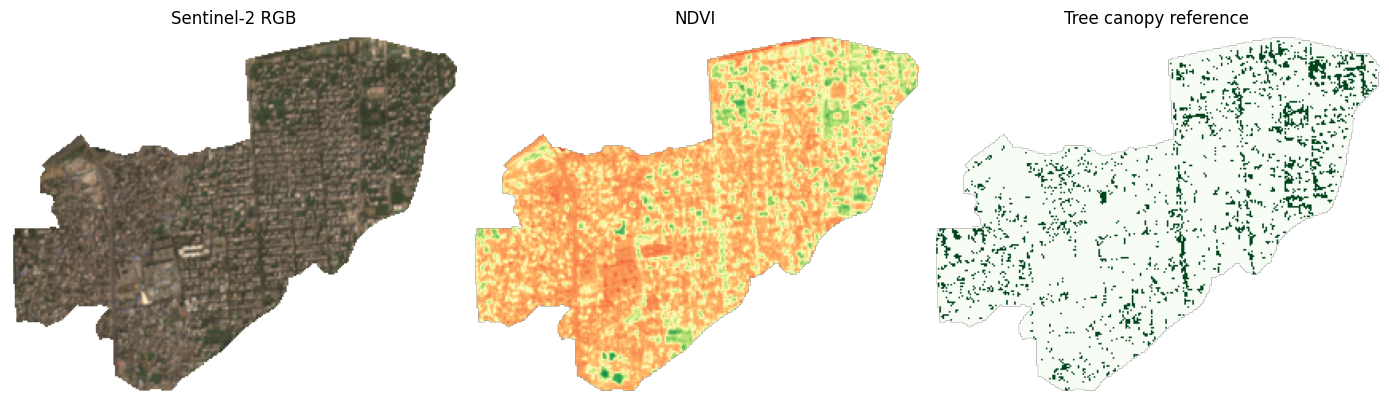

In [3]:

import matplotlib.pyplot as plt

# RGB, NDVI and canopy reference
rgb = np.clip(X[:, :, [2, 1, 0]] / 0.3, 0, 1)
rgb[~inside] = 1

ndvi = np.ma.masked_where(~inside, X[:, :, 4])
trees = np.ma.masked_where(~inside, y)

fig, ax = plt.subplots(1, 3, figsize=(14, 5))

ax[0].imshow(rgb)
ax[0].set_title('Sentinel-2 RGB')

ax[1].imshow(ndvi, cmap='RdYlGn', vmin=-0.2, vmax=0.8)
ax[1].set_title('NDVI')

ax[2].imshow(trees, cmap='Greens', vmin=0, vmax=1)
ax[2].set_title('Tree canopy reference')

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


In [4]:

# Split the image into training, validation and test areas

height, width = y.shape
patch_size = 32
stride = 16

train_end = int(width * 0.6)
val_end = int(width * 0.8)

def make_patches(start, end):
    images, labels, masks = [], [], []

    for row in range(0, height - patch_size + 1, stride):
        for col in range(start, end - patch_size + 1, stride):

            img = X[row:row+patch_size, col:col+patch_size]
            label = y[row:row+patch_size, col:col+patch_size]
            mask = valid[row:row+patch_size, col:col+patch_size]

            if mask.mean() < 0.7:
                continue

            images.append(img)
            labels.append(label)
            masks.append(mask)

    return np.array(images), np.array(labels), np.array(masks)

X_train, y_train, m_train = make_patches(0, train_end)
X_val, y_val, m_val = make_patches(train_end, val_end)
X_test, y_test, m_test = make_patches(val_end, width)

len(X_train), len(X_val), len(X_test)


(57, 16, 9)

In [5]:
# Prepare image patches for U-Net training

import torch
from torch.utils.data import Dataset, DataLoader

class CanopyDataset(Dataset):
    def __init__(self, images, labels, masks, augment=False):
        self.images = images
        self.labels = labels
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i].copy()
        label = self.labels[i].copy()
        mask = self.masks[i].copy()

        # Random flips for training
        if self.augment and np.random.rand() < 0.5:
            img = np.flip(img, axis=1)
            label = np.flip(label, axis=1)
            mask = np.flip(mask, axis=1)

        if self.augment and np.random.rand() < 0.5:
            img = np.flip(img, axis=0)
            label = np.flip(label, axis=0)
            mask = np.flip(mask, axis=0)

        img = np.ascontiguousarray(img.transpose(2, 0, 1))
        label = np.ascontiguousarray(label[None])
        mask = np.ascontiguousarray(mask[None])

        return (
            torch.from_numpy(img).float(),
            torch.from_numpy(label).float(),
            torch.from_numpy(mask).float()
        )

train_data = CanopyDataset(X_train, y_train, m_train, augment=True)
val_data = CanopyDataset(X_val, y_val, m_val)
test_data = CanopyDataset(X_test, y_test, m_test)

train_loader = DataLoader(train_data, batch_size=4, shuffle=True)
val_loader = DataLoader(val_data, batch_size=4)
test_loader = DataLoader(test_data, batch_size=4)

len(train_loader), len(val_loader), len(test_loader)


(15, 4, 3)

In [6]:

# Build a small U-Net for tree canopy segmentation

import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(5, 16)
        self.enc2 = DoubleConv(16, 32)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(32, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))

        b = self.bottleneck(self.pool(e2))

        d2 = self.up2(b)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


model = UNet().to(device)

sum(p.numel() for p in model.parameters())


117329

In [7]:

# Train U-Net and save the best model

import torch.nn.functional as F
from pathlib import Path

torch.manual_seed(42)
np.random.seed(42)

optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
pos_weight = torch.tensor(2.0, device=device)

output_dir = Path('/content/drive/MyDrive/Badda_Tree_Canopy_2021/Clean_Results')
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / 'best_unet.pth'

def masked_loss(pred, target, mask):
    loss = F.binary_cross_entropy_with_logits(
        pred, target, pos_weight=pos_weight, reduction='none'
    )
    return (loss * mask).sum() / mask.sum().clamp(min=1)

train_losses = []
val_losses = []
best_loss = float('inf')
patience = 8
wait = 0

for epoch in range(50):
    model.train()
    train_loss = 0

    for images, labels, masks in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        loss = masked_loss(model(images), labels, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, labels, masks in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            masks = masks.to(device)

            val_loss += masked_loss(model(images), labels, masks).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_loss - 0.0001:
        best_loss = val_loss
        wait = 0
        torch.save(model.state_dict(), model_path)
    else:
        wait += 1

    print(f'Epoch {epoch+1:02d} | Train: {train_loss:.4f} | Val: {val_loss:.4f}')

    if wait >= patience:
        break


Epoch 01 | Train: 0.8348 | Val: 0.8093
Epoch 02 | Train: 0.6348 | Val: 0.7165
Epoch 03 | Train: 0.5039 | Val: 0.5876
Epoch 04 | Train: 0.4831 | Val: 0.5862
Epoch 05 | Train: 0.4845 | Val: 0.5929
Epoch 06 | Train: 0.4722 | Val: 0.5839
Epoch 07 | Train: 0.4613 | Val: 0.5821
Epoch 08 | Train: 0.4596 | Val: 0.5658
Epoch 09 | Train: 0.4563 | Val: 0.5545
Epoch 10 | Train: 0.4356 | Val: 0.5535
Epoch 11 | Train: 0.4330 | Val: 0.5426
Epoch 12 | Train: 0.4365 | Val: 0.5251
Epoch 13 | Train: 0.4150 | Val: 0.5219
Epoch 14 | Train: 0.4220 | Val: 0.5202
Epoch 15 | Train: 0.4174 | Val: 0.5188
Epoch 16 | Train: 0.4094 | Val: 0.5164
Epoch 17 | Train: 0.4027 | Val: 0.5197
Epoch 18 | Train: 0.4012 | Val: 0.5136
Epoch 19 | Train: 0.4158 | Val: 0.5147
Epoch 20 | Train: 0.4088 | Val: 0.5144
Epoch 21 | Train: 0.4045 | Val: 0.5117
Epoch 22 | Train: 0.4081 | Val: 0.5110
Epoch 23 | Train: 0.3870 | Val: 0.5184
Epoch 24 | Train: 0.3886 | Val: 0.5156
Epoch 25 | Train: 0.3895 | Val: 0.5139
Epoch 26 | Train: 0.4048 

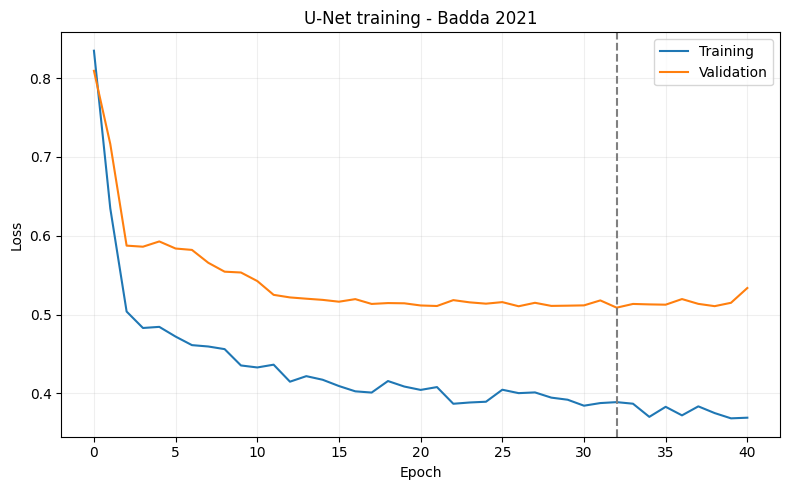

In [8]:

# Plot training and validation loss

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')

plt.axvline(np.argmin(val_losses), color='gray', linestyle='--')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('U-Net training - Badda 2021')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [9]:

# Predict tree canopy in the validation area

from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
model.eval()

height, width = y.shape
prob_sum = np.zeros((height, width), dtype=np.float32)
prob_count = np.zeros((height, width), dtype=np.float32)

with torch.no_grad():
    for row in range(0, height - patch_size + 1, stride):
        for col in range(train_end, val_end - patch_size + 1, stride):
            mask = valid[row:row+patch_size, col:col+patch_size]

            if mask.mean() < 0.7:
                continue

            patch = X[row:row+patch_size, col:col+patch_size]
            tensor = torch.from_numpy(patch.transpose(2, 0, 1).copy()).float().unsqueeze(0).to(device)

            prob = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()

            prob_sum[row:row+patch_size, col:col+patch_size] += prob * mask
            prob_count[row:row+patch_size, col:col+patch_size] += mask

val_prob = np.divide(prob_sum, prob_count, out=np.zeros_like(prob_sum), where=prob_count > 0)
val_mask = (prob_count > 0) & valid

val_true = y[val_mask].astype(np.uint8)
val_scores = val_prob[val_mask]

len(val_true), int(val_true.sum())


(6709, 701)

In [10]:

# Find the best probability threshold using validation F1

import pandas as pd

results = []

for t in np.arange(0.1, 0.81, 0.05):
    pred = (val_scores >= t).astype(np.uint8)

    results.append({
        'Threshold': round(float(t), 2),
        'Precision': precision_score(val_true, pred, zero_division=0),
        'Recall': recall_score(val_true, pred, zero_division=0),
        'F1': f1_score(val_true, pred, zero_division=0),
        'IoU': jaccard_score(val_true, pred, zero_division=0)
    })

val_results = pd.DataFrame(results)
best = val_results.loc[val_results['F1'].idxmax()]
best_threshold = float(best['Threshold'])

display(val_results.round(3))
print('Best threshold:', best_threshold)
print('Validation F1:', round(best['F1'], 3))


,Threshold,Precision,Recall,F1,IoU
0,0.10,0.146,0.869,0.250,0.143
1,0.15,0.167,0.789,0.275,0.160
2,0.20,0.191,0.728,0.302,0.178
3,0.25,0.217,0.659,0.326,0.195
4,0.30,0.233,0.525,0.323,0.192
5,0.35,0.271,0.389,0.320,0.190
6,0.40,0.305,0.227,0.260,0.149
7,0.45,0.284,0.086,0.132,0.070
8,0.50,0.360,0.039,0.070,0.036
9,0.55,0.421,0.011,0.022,0.011


Best threshold: 0.25
Validation F1: 0.326


In [11]:

# Compare U-Net with an NDVI threshold classifier

ndvi_scores = X[:, :, 4][val_mask]
ndvi_results = []

for t in np.arange(0.05, 0.61, 0.01):
    pred = (ndvi_scores >= t).astype(np.uint8)

    ndvi_results.append({
        'Threshold': round(float(t), 2),
        'Precision': precision_score(val_true, pred, zero_division=0),
        'Recall': recall_score(val_true, pred, zero_division=0),
        'F1': f1_score(val_true, pred, zero_division=0),
        'IoU': jaccard_score(val_true, pred, zero_division=0)
    })

ndvi_results = pd.DataFrame(ndvi_results)
ndvi_best = ndvi_results.loc[ndvi_results['F1'].idxmax()]
ndvi_threshold = float(ndvi_best['Threshold'])

comparison = pd.DataFrame([
    {'Model': 'U-Net', 'Threshold': best_threshold,
     'F1': best['F1'], 'IoU': best['IoU']},
    {'Model': 'NDVI', 'Threshold': ndvi_threshold,
     'F1': ndvi_best['F1'], 'IoU': ndvi_best['IoU']}
])

display(comparison.round(3))


,Model,Threshold,F1,IoU
0,U-Net,0.25,0.326,0.195
1,NDVI,0.31,0.354,0.215


In [12]:

# Compare U-Net and NDVI on the test area

prob_sum = np.zeros((height, width), dtype=np.float32)
prob_count = np.zeros((height, width), dtype=np.float32)

model.eval()

with torch.no_grad():
    for row in range(0, height - patch_size + 1, stride):
        for col in range(val_end, width - patch_size + 1, stride):
            mask = valid[row:row+patch_size, col:col+patch_size]

            if mask.mean() < 0.7:
                continue

            patch = X[row:row+patch_size, col:col+patch_size]
            tensor = torch.from_numpy(patch.transpose(2, 0, 1).copy()).float().unsqueeze(0).to(device)
            prob = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()

            prob_sum[row:row+patch_size, col:col+patch_size] += prob * mask
            prob_count[row:row+patch_size, col:col+patch_size] += mask

test_prob = np.divide(prob_sum, prob_count, out=np.zeros_like(prob_sum), where=prob_count > 0)
test_mask = (prob_count > 0) & valid

test_true = y[test_mask].astype(np.uint8)
unet_pred = (test_prob[test_mask] >= best_threshold).astype(np.uint8)
ndvi_pred = (X[:, :, 4][test_mask] >= ndvi_threshold).astype(np.uint8)

def evaluate(name, pred):
    return {
        'Model': name,
        'Precision': precision_score(test_true, pred, zero_division=0),
        'Recall': recall_score(test_true, pred, zero_division=0),
        'F1': f1_score(test_true, pred, zero_division=0),
        'IoU': jaccard_score(test_true, pred, zero_division=0)
    }

test_results = pd.DataFrame([
    evaluate('U-Net', unet_pred),
    evaluate('NDVI', ndvi_pred)
])

display(test_results.round(3))


,Model,Precision,Recall,F1,IoU
0,U-Net,0.254,0.815,0.387,0.240
1,NDVI,0.305,0.681,0.421,0.267


In [13]:

# Predict canopy across the whole ward

pad = patch_size // 2
X_pad = np.pad(X, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')

h, w = X_pad.shape[:2]
prob_sum = np.zeros((h, w), dtype=np.float32)
prob_count = np.zeros((h, w), dtype=np.float32)

rows = list(range(0, h - patch_size + 1, stride))
cols = list(range(0, w - patch_size + 1, stride))

if rows[-1] != h - patch_size:
    rows.append(h - patch_size)

if cols[-1] != w - patch_size:
    cols.append(w - patch_size)

model.eval()

with torch.no_grad():
    for row in rows:
        for col in cols:
            patch = X_pad[row:row+patch_size, col:col+patch_size]
            tensor = torch.from_numpy(patch.transpose(2, 0, 1).copy()).float().unsqueeze(0).to(device)

            prob = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()

            prob_sum[row:row+patch_size, col:col+patch_size] += prob
            prob_count[row:row+patch_size, col:col+patch_size] += 1

full_prob = (prob_sum / prob_count)[pad:pad+height, pad:pad+width]

unet_map = (full_prob >= best_threshold).astype(np.uint8)
ndvi_map = (X[:, :, 4] >= ndvi_threshold).astype(np.uint8)

unet_map[~inside] = 0
ndvi_map[~inside] = 0

unet_map.shape, ndvi_map.shape


((230, 281), (230, 281))

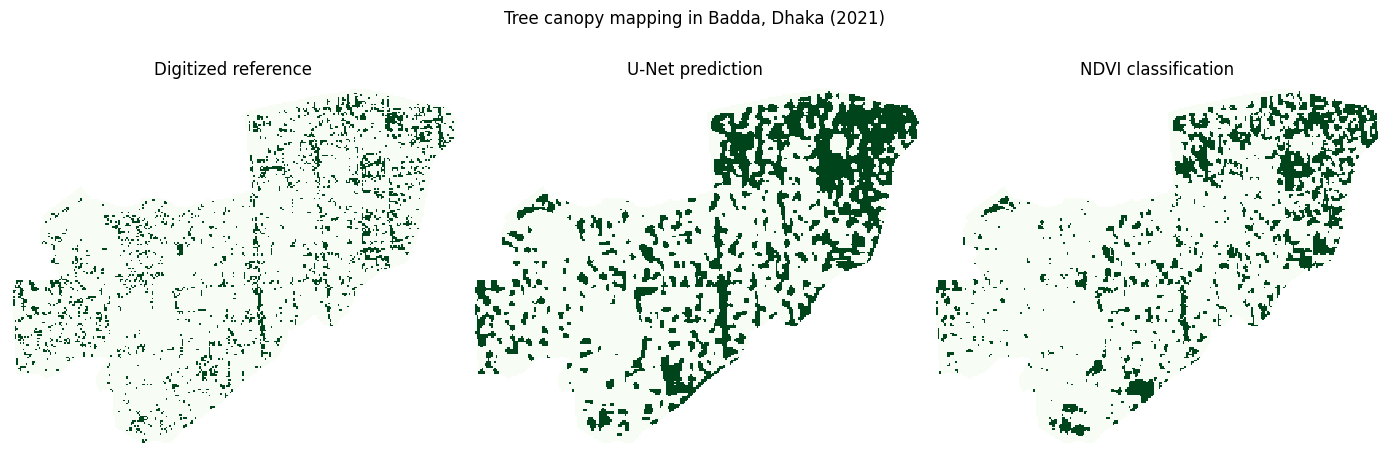

In [14]:

# Compare the reference and predicted canopy maps

reference = np.ma.masked_where(~inside, y)
unet_display = np.ma.masked_where(~inside, unet_map)
ndvi_display = np.ma.masked_where(~inside, ndvi_map)

fig, ax = plt.subplots(1, 3, figsize=(14, 5))

maps = [reference, unet_display, ndvi_display]
titles = ['Digitized reference', 'U-Net prediction', 'NDVI classification']

for i in range(3):
    ax[i].imshow(maps[i], cmap='Greens', vmin=0, vmax=1, interpolation='nearest')
    ax[i].set_title(titles[i])
    ax[i].axis('off')

plt.suptitle('Tree canopy mapping in Badda, Dhaka (2021)')
plt.tight_layout()
plt.show()


In [15]:

# Save canopy maps and calculate area

import pandas as pd

results_dir = output_dir / 'GIS_Outputs'
results_dir.mkdir(parents=True, exist_ok=True)

def save_raster(name, array, nodata):
    p = profile.copy()
    p.update(count=1, dtype=array.dtype, nodata=nodata, compress='lzw')

    with rasterio.open(results_dir / name, 'w', **p) as dst:
        dst.write(array, 1)

def binary_output(array):
    return np.where(inside, array, 255).astype(np.uint8)

save_raster('Badda_UNet_2021.tif', binary_output(unet_map), 255)
save_raster('Badda_NDVI_2021.tif', binary_output(ndvi_map), 255)
save_raster('Badda_Reference_2021.tif', binary_output(y), 255)

prob_output = np.where(inside, full_prob, -9999).astype(np.float32)
save_raster('Badda_UNet_Probability_2021.tif', prob_output, -9999)

# Pixel area from the projected raster
if not profile['crs'].is_projected:
    raise ValueError('A projected CRS is required for area calculations.')

pixel_area = abs(profile['transform'].a * profile['transform'].e)
aoi_ha = inside.sum() * pixel_area / 10000

areas = []
for name, arr in [('Reference', y), ('U-Net', unet_map), ('NDVI', ndvi_map)]:
    tree_ha = ((arr > 0.5) & inside).sum() * pixel_area / 10000
    areas.append({
        'Method': name,
        'Canopy area (ha)': tree_ha,
        'Canopy cover (%)': 100 * tree_ha / aoi_ha
    })

area_table = pd.DataFrame(areas)
display(area_table.round(2))

area_table.to_csv(results_dir / 'Badda_Canopy_Area_2021.csv', index=False)
test_results.to_csv(results_dir / 'Badda_Test_Results_2021.csv', index=False)


,Method,Canopy area (ha),Canopy cover (%)
0,Reference,35.68,10.87
1,U-Net,100.43,30.59
2,NDVI,57.63,17.55


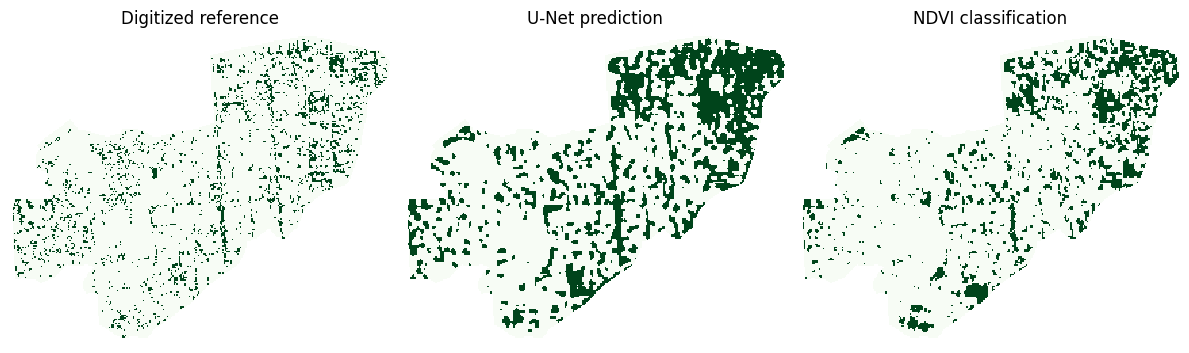

In [16]:

# Save canopy comparison figure

fig, ax = plt.subplots(1, 3, figsize=(12, 5))

maps = [reference, unet_display, ndvi_display]
titles = ['Digitized reference', 'U-Net prediction', 'NDVI classification']

for i in range(3):
    ax[i].imshow(maps[i], cmap='Greens', vmin=0, vmax=1, interpolation='nearest')
    ax[i].set_title(titles[i])
    ax[i].axis('off')

plt.tight_layout()
plt.savefig(results_dir / 'Badda_Canopy_Comparison_2021.png',
            dpi=200, bbox_inches='tight')
plt.show()
